# Example: The Thermal Minority Game
In this example, we simulate the minority game, an agent-based model in which an odd number of agents decide to buy or sell each round and the agents on the minority side win. Each agent chooses among a few fixed policies, and in the thermal version it makes that choice with Boltzmann probabilities set by a temperature.

> __Learning Objectives:__
>
> By the end of this example, you should be able to:
> * __Simulate one minority game:__ We simulate one minority game, plot the attendance, compute the volatility of the attendance per agent, and let the attendance move a price whose growth rates we check for the stylized facts.
> * __Measure how the memory changes the price volatility:__ We hold the number of agents and the liquidity fixed, vary the memory, and measure the annualized volatility of the growth rates. We compare it with a market of agents who flip coins.
> * __Measure how the temperature changes the price volatility:__ The temperature sets how strongly an agent favors its best-scoring policy. We vary the temperature in the crowded game and compare the price volatility with that of the greedy game and of random policy choice.

We compare every volatility with the value for agents who flip fair coins, which is one per agent.

Let's get started!
___

## Setup, Data, and Prerequisites
First, we set up the computational environment by including the `Include.jl` file and loading any needed resources.

> __Include:__ The [`include(...)` command](https://docs.julialang.org/en/v1/base/base/#include) evaluates the contents of the input source file, `Include.jl`, in the notebook's global scope. The `Include.jl` file sets paths, loads required external packages, etc. For additional information on functions and types used in this material, see the [Julia programming language documentation](https://docs.julialang.org/en/v1/).

Let's set up our code environment:

In [1]:
include(joinpath(@__DIR__, "Include.jl")); # include the Include.jl file

  Activating project at `~/Desktop/julia_work/CHEME-5660-CourseRepository-Fall-2026`


For additional information on functions and types used in this material, see the [Julia programming language documentation](https://docs.julialang.org/en/v1/) and the [CHEME 5660 Quantitative Finance Package documentation](https://varnerlab.org/CHEME-5660-CourseRepository-Fall-2026/dev/).

### Constants
Next, let's set the constants. See the comments next to the constants for definitions, units, and permissible values.

In [2]:
# the minority game -
m = 6; # memory: the number of past minority actions every agent sees
P = 2^m; # number of possible histories (information states)
J = 2; # number of policies each agent holds
N_crowded = 641; # number of agents in the crowded game of Tasks 1 and 3 (odd, so the attendance is never zero); α = P/N ≈ 0.1

# the simulation -
number_of_rounds = 10_000; # rounds we record in every game, after the burn-in
burn_in = 2_000; # rounds we play first and discard, so the scores move away from their starting value of zero
number_of_seeds = 3; # independent games at each setting in Tasks 2 and 3
random_seed = 5660; # fix the random numbers, so every run gives the same games

# the price (instructor's extension) -
m_near = 8; # memory of the comparison game in Task 1: P = 2^8 = 256 histories, so α = 256/641 ≈ 0.40
λ = 1_000.0; # liquidity: the attendance (number of agents) that moves the log price by one
σ_S = 0.03; # annualized volatility of the price noise (1/√yr); the noise added in one round has standard deviation σ_S√Δt
S₀ = 1.0; # price at the start of the first recorded round, t = 0 (USD/share)
price_window = 500; # number of recorded rounds in the price plot
noise_model = :normal; # distribution of the standardized noise Z: :normal or :studentt (both with mean 0 and variance 1)
ν = 5.0; # degrees of freedom of the Student-t noise, used when noise_model = :studentt (must be > 4, so the kurtosis is finite)
Δt = 1/252; # length of one round (years), taking one round as one trading day
lags = [1, 5, 20]; # lags (rounds) at which we report autocorrelations
buy_probability = 0.5; # probability b that a policy entry is buy (+1) in Task 1's games; 0.5 gives unbiased policies

___

## Task 1: Simulate One Minority Game
In this task, we simulate one greedy minority game with `N_crowded` agents, where every agent uses its best-scoring policy. We measure how far the attendance moves from zero, and then we let the attendance move a price.

__Simulate the game__: [The build(...) function](https://varnerlab.org/CHEME-5660-CourseRepository-Fall-2026/dev/abm/#VLQuantitativeFinancePackage.build-Tuple{Type{MyThermalMinorityGameModel},%20NamedTuple}) draws the policies of every agent at random and returns a `MyThermalMinorityGameModel`, and [the solve(...) function](https://varnerlab.org/CHEME-5660-CourseRepository-Fall-2026/dev/abm/#VLQuantitativeFinancePackage.solve-Tuple{MyThermalMinorityGameModel}) plays the game. In the code below:
* We pass the number of agents, the memory `m`, the number of policies `J`, the temperature, and a [`MersenneTwister`](https://docs.julialang.org/en/v1/stdlib/Random/#Random.MersenneTwister) random number generator `rng` to `build(...)`.
* `solve(...)` first plays `burn_in` rounds and discards them, then records `number_of_rounds` rounds. The scores start at zero, and we want to measure the game after they have moved away from that start.
* The result `game::NamedTuple` holds the attendance `attendance::Vector{Int}`, the history of each round `information::Vector{Int}`, the volatility per agent `volatility_per_agent::Float64`, the number of histories per agent `alpha::Float64` ($\alpha=P/N$), and the final scores `final_scores::Array{Float64,2}`, one row per agent and one column per policy.

Let's simulate the game:

In [3]:
game = let

    # initialize: a random number generator with a fixed seed, so every run gives the same game -
    rng = MersenneTwister(random_seed);

    # build the game: draw J random policies for each of the N agents -
    model = build(MyThermalMinorityGameModel, (
        N = N_crowded, # number of agents (odd)
        m = m, # memory: the number of past minority actions in the history
        J = J, # policies per agent
        temperature = 0.0, # 0.0 selects the greedy rule: every agent uses its best-scoring policy
        buy_probability = buy_probability, # probability that a policy entry is buy (+1)
        rng = rng # random number generator for the policies
    ));

    # play the game: discard the burn-in rounds, then record number_of_rounds rounds -
    result = solve(model; number_of_rounds = number_of_rounds, burn_in = burn_in, rng = rng);

    # checks: one attendance per recorded round, and A_t is odd, so never zero -
    @assert length(result.attendance) == number_of_rounds "one attendance per recorded round"
    @assert all(isodd, result.attendance) "with an odd number of agents, the attendance is odd"

    # return -
    result
end;

Let's put the size of the game and its volatility per agent in a [`DataFrame`](https://dataframes.juliadata.org/stable/lib/types/#DataFrames.DataFrame) and display the table with [the `pretty_table(...)` function](https://ronisbr.github.io/PrettyTables.jl/stable/lib/library/#PrettyTables.pretty_table):

In [4]:
let

    # build the table: the size of the game and the volatility per agent -
    df = DataFrame(
        quantity = ["number of agents N", "memory m", "number of histories P = 2^m", "histories per agent α = P/N", "volatility per agent σ_A²/N"],
        value = [string(N_crowded), string(m), string(P), string(round(game.alpha, digits = 4)), string(round(game.volatility_per_agent, digits = 3))]
    );

    # show the table -
    pretty_table(df; column_labels = ["quantity", "value"], alignment = [:l, :r],
        table_format = TextTableFormat(borders = text_table_borders__compact), fit_table_in_display_horizontally = false);
end

 ----------------------------- --------
  quantity                       value 
 ----------------------------- --------
  number of agents N               641
  memory m                           6
  number of histories P = 2^m       64
  histories per agent α = P/N   0.0998
  volatility per agent σ_A²/N    2.804
 ----------------------------- --------


> __What do we see?__ The volatility per agent is well above 1, the value for coin flips. With many more agents than histories, the attendance moves much farther from zero than it would if every agent flipped a coin.

`Unhide` the code block below to see how we plotted the attendance for the first 200 recorded rounds. The dashed lines at $\pm\sqrt{N}$ mark one standard deviation of the attendance for coin flips.

How does the attendance move from round to round?

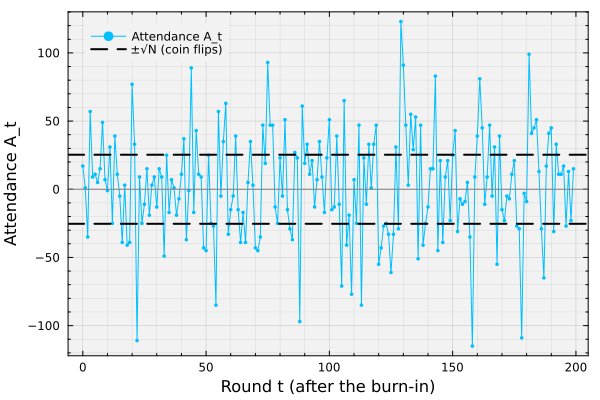

In [5]:
let

    # initialize: the first 200 recorded rounds -
    window = 0:199; # rounds t to plot
    A = game.attendance[window .+ 1]; # attendance A_t in those rounds (Julia index t + 1)
    band = sqrt(N_crowded); # one standard deviation of the attendance for coin flips

    # plot: the attendance in each round -
    plot(window, A, lw = 1, c = :deepskyblue1, marker = :circle, ms = 2, msw = 0, label = "Attendance A_t",
        bg = "gray95", background_color_outside = "white", framestyle = :box, fg_legend = :transparent,
        xminorticks = true, yminorticks = true, minorgrid = true, legend = :topleft)
    hline!([band, -band], lw = 2, c = :black, ls = :dash, label = "±√N (coin flips)") # one standard deviation for coin flips
    hline!([0.0], lw = 1, c = :gray, label = "") # an even split between buyers and sellers

    # labels -
    xlabel!("Round t (after the burn-in)", fontsize = 18)
    ylabel!("Attendance A_t", fontsize = 18)
end

> __What do we see?__ The attendance swings far from zero in both directions, and many rounds land outside the dashed lines, one coin-flip standard deviation from zero. Large majorities of buyers and large majorities of sellers both occur, often within a few rounds of each other.

### From the attendance to a price
The original minority game has no price. In the lecture, we added one as an instructor's extension: a market maker treats the attendance as the excess demand for the asset and moves the log price:

$$
\ln S_{t+1} = \ln S_{t} + \frac{A_{t}}{\lambda} + \sigma_{S}\sqrt{\Delta t}\,Z_{t+1}
$$

where the liquidity $\lambda$ is the attendance that moves the log price by one, and $\sigma_{S}$ is the annualized volatility of the price noise. The draw $Z_{t+1}$ is standard Normal unless we set `noise_model = :studentt`. Because the agents never see the price, we compute it from the attendance after the game is played, starting from $S_{0}$ at $t=0$.

__Compare two markets__: We compare the crowded game we just played ($\alpha\approx 0.1$) with a second game of `N_crowded` agents that differs only in its memory, `m_near`. That game has $\alpha\approx 0.40$. In the code below:
* A separate random number generator `price_rng` draws one noise value $Z_{t+1}$ for each recorded round. Because both prices use these draws, the two price paths differ only through their attendances.
* The result `markets::Vector{NamedTuple}` holds, for each game, its name, $\alpha$, and its log prices, starting from $\ln S_{0}$.

Let's compute the two prices:

In [6]:
markets = let

    # initialize: a second, separately built game with the same number of agents and settings as Task 1, except the memory -
    rng = MersenneTwister(random_seed); # same seed as Task 1
    model = build(MyThermalMinorityGameModel, (N = N_crowded, m = m_near, J = J, temperature = 0.0, buy_probability = buy_probability, rng = rng)); # P = 2^m_near histories
    near = solve(model; number_of_rounds = number_of_rounds, burn_in = burn_in, rng = rng); # play the game

    # draw one standardized noise path Z_1, ..., Z_R, shared by both prices, from its own random number generator -
    price_rng = MersenneTwister(random_seed + 1); # separate from the games
    Z = if noise_model == :normal # change this line to :studentt to use Student-t noise instead of Normal noise
        randn(price_rng, number_of_rounds); # Z[t] is Z_t, the standard Normal draw added at the end of recorded round t - 1
    else
        sqrt((ν - 2)/ν) .* rand(price_rng, TDist(ν), number_of_rounds); # Student-t, rescaled to unit variance
    end

    # main loop: the market maker turns each attendance into a log price -
    results = NamedTuple[];
    for (name, result) ∈ [("crowded game, m = $(m)", game), ("longer memory, m = $(m_near)", near)]
        A = result.attendance; # attendance in each recorded round; A[t] holds A_{t-1}
        log_S = Vector{Float64}(undef, number_of_rounds + 1); # Julia index k holds ln S_{k-1}: ln S_0, ..., ln S_R
        log_S[1] = log(S₀); # starting price ln S_0
        for t ∈ 1:number_of_rounds
            log_S[t+1] = log_S[t] + A[t]/λ + σ_S*sqrt(Δt)*Z[t]; # ln S_t = ln S_{t-1} + A_{t-1}/λ + σ_S√Δt Z_t, in the Julia index
        end
        push!(results, (name = name, alpha = result.alpha, log_price = log_S));
    end

    # checks: a known noise model, one log price per round plus the start, and every price is finite -
    @assert noise_model ∈ (:normal, :studentt) "noise_model must be :normal or :studentt"
    @assert noise_model == :normal || ν > 4 "the Student-t noise needs ν > 4 for a finite standard deviation and kurtosis"
    @assert all(length(r.log_price) == number_of_rounds + 1 for r ∈ results) "one log price per recorded round, plus the start"
    @assert all(all(isfinite, r.log_price) for r ∈ results) "the log prices must be finite"

    # return -
    results
end;

`Unhide` the code block below to see how we plotted the price $S_{t}$ of both markets for the first `price_window` recorded rounds. Both prices start at `S₀` and share the same noise path.

How do the prices of the two markets move?

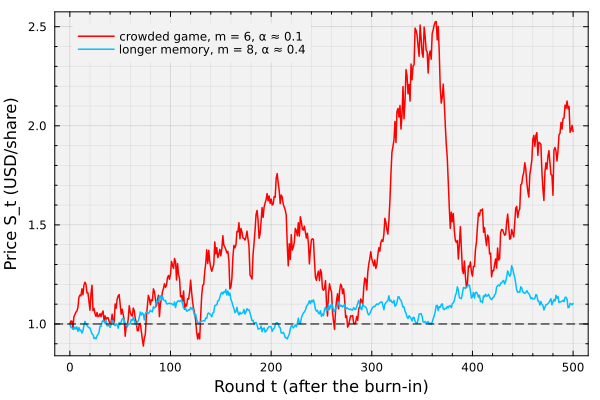

In [7]:
let

    # initialize: the first price_window + 1 prices of each market -
    window = 1:(price_window + 1); # Julia indices of S_0, ..., S_(price_window)
    colors = [:red, :deepskyblue1]; # crowded game, longer-memory game

    # plot: the price S_t = exp(ln S_t) in each market -
    plot(bg = "gray95", background_color_outside = "white", framestyle = :box, fg_legend = :transparent,
        xminorticks = true, yminorticks = true, minorgrid = true, legend = :topleft)
    for (k, r) ∈ enumerate(markets)
        plot!(window .- 1, exp.(r.log_price[window]), lw = 1.5, c = colors[k], label = "$(r.name), α ≈ $(round(r.alpha, digits = 2))")
    end
    hline!([S₀], lw = 1, c = :black, ls = :dash, label = "") # the starting price

    # labels -
    xlabel!("Round t (after the burn-in)", fontsize = 18)
    ylabel!("Price S_t (USD/share)", fontsize = 18)
end

> __What do we see?__ The crowded game's price booms and busts. It climbs to about two and a half times its starting value, then loses about half of that within a few dozen rounds. The price of the longer-memory game stays within about 30% of its start.

__Growth rates and stylized facts__: If one round lasts $\Delta t$ years, the growth rate over round $t$ follows directly from the price rule:

$$
g_{t+1}=\frac{1}{\Delta t}\ln\frac{S_{t+1}}{S_{t}}=\underbrace{\frac{A_{t}}{\lambda\,\Delta t}}_{\text{agents}}+\underbrace{\frac{\sigma_{S}}{\sqrt{\Delta t}}\,Z_{t+1}}_{\text{price noise}}
$$

We measure the three stylized facts of daily growth rates for both markets: the excess kurtosis (fat tails), the autocorrelation of $g$ (little autocorrelation), and the autocorrelation of $\lvert g\rvert$ (volatility clustering). 

In the code below:
* `excess_kurtosis(...)` is the fourth moment of the standardized series minus 3, which is zero for a Normal distribution. If the series has fat tails, the excess kurtosis is positive.
* [The stylized_facts_report(...) function](https://varnerlab.org/CHEME-5660-CourseRepository-Fall-2026/dev/adaptive/#VLQuantitativeFinancePackage.stylized_facts_report) returns the autocorrelations of $g$ and $\lvert g\rvert$ at each lag in `lags`, and the white-noise band $\pm 1.96/\sqrt{n}$, where $n$ is the length of the series. For a series with no autocorrelation, 95% of sample autocorrelations fall inside this band. A value outside the band is unlikely to be noise.

Let's compute the stylized facts:

In [8]:
# excess kurtosis: the fourth moment of the standardized series, minus 3 (zero for a Normal distribution) -
excess_kurtosis(x) = mean(((x .- mean(x)) ./ std(x, corrected = false)).^4) - 3;

In [9]:
let

    # initialize: the growth rates of each market and their stylized facts -
    growth = [(1/Δt) .* diff(r.log_price) for r ∈ markets]; # g_{t+1} = (1/Δt) ln(S_{t+1}/S_t) (1/yr)
    reports = [stylized_facts_report(g; lags = lags) for g ∈ growth]; # autocorrelations of g and |g|, white-noise band

    # build the table: one row per market -
    df = DataFrame(market = [r.name for r ∈ markets], kurtosis = [excess_kurtosis(g) for g ∈ growth]);
    for (k, l) ∈ enumerate(lags)
        df[!, "acf_g_$(l)"] = [rep.raw_acf[k] for rep ∈ reports]; # autocorrelation of g at lag l
    end
    for (k, l) ∈ enumerate(lags)
        df[!, "acf_abs_$(l)"] = [rep.absolute_acf[k] for rep ∈ reports]; # autocorrelation of |g| at lag l
    end
    df[!, "band"] = [rep.white_noise_95_band for rep ∈ reports]; # white-noise band (±)
    pretty_table(df; column_labels = ["market"; "excess kurtosis"; ["acf g, lag $(l)" for l ∈ lags]; ["acf |g|, lag $(l)" for l ∈ lags]; "band (±)"],
        alignment = [:l; fill(:r, ncol(df) - 1)], formatters = [fmt__printf("%.3f", collect(2:ncol(df)))],
        table_format = TextTableFormat(borders = text_table_borders__compact), fit_table_in_display_horizontally = false);

    # checks: one growth rate per recorded round in each market -
    @assert all(length(g) == number_of_rounds for g ∈ growth) "one growth rate per recorded round"
end

 ---------------------- ----------------- -------------- -------------- --------------- ---------------- ---------------- ----------------- ----------
  market                 excess kurtosis   acf g, lag 1   acf g, lag 5   acf g, lag 20   acf |g|, lag 1   acf |g|, lag 5   acf |g|, lag 20   band (±) 
 ---------------------- ----------------- -------------- -------------- --------------- ---------------- ---------------- ----------------- ----------
  crowded game, m = 6              1.080         -0.001         -0.002          -0.004            0.004            0.002             0.000      0.020
  longer memory, m = 8             0.108         -0.001         -0.010          -0.013            0.040            0.018             0.000      0.020
 ---------------------- ----------------- -------------- -------------- --------------- ---------------- ---------------- ----------------- ----------


> __What do we see?__
>
> * __Fat tails:__ The crowded game's growth rates have an excess kurtosis of about 1, mild fat tails that come from the agents, because Normal noise has no excess kurtosis of its own. The growth rates of the longer-memory game have an excess kurtosis near zero, like a Normal distribution.
> * __Autocorrelation and clustering:__ In both markets, every autocorrelation of $g$ is inside the white-noise band. Only the longer-memory game shows volatility clustering, above the band at lag 1 and inside it by lag 5, while the clustering of the `SPY` growth rates in the Farmer–Joshi example lasts for weeks.

`Unhide` the code block below to see how we plotted the distribution of the growth rates in both markets. The dashed black curves are the Normal distributions with the same mean and variance as each market.

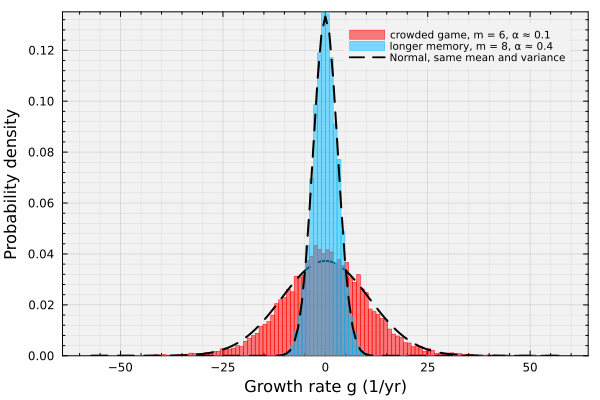

In [10]:
let

    # initialize: the growth rates of each market and one set of bins for both -
    growth = [(1/Δt) .* diff(r.log_price) for r ∈ markets]; # g_{t+1} = (1/Δt) ln(S_{t+1}/S_t) (1/yr)
    colors = [:red, :deepskyblue1]; # crowded game, longer-memory game (the same colors as the price plot)
    largest = maximum(maximum(abs, g) for g ∈ growth); # largest |g| in either market (1/yr)
    edges = range(-largest, largest, length = 121); # the same bins for both markets, so we can compare them

    # plot: the distribution of g in each market, with a Normal of the same mean and variance -
    plot(bg = "gray95", background_color_outside = "white", framestyle = :box, fg_legend = :transparent,
        xminorticks = true, yminorticks = true, minorgrid = true, legend = :topright, legendfontsize = 7)
    for (k, r) ∈ enumerate(markets)
        histogram!(growth[k], bins = edges, normalize = :pdf, fillalpha = 0.5, c = colors[k], linecolor = colors[k], lw = 0.5,
            label = "$(r.name), α ≈ $(round(r.alpha, digits = 2))")
        fitted = Normal(mean(growth[k]), std(growth[k])); # the Normal with this market's mean and standard deviation
        plot!(edges, pdf.(fitted, edges), lw = 2, c = :black, ls = :dash, label = k == 2 ? "Normal, same mean and variance" : "")
    end

    # labels -
    xlabel!("Growth rate g (1/yr)", fontsize = 18)
    ylabel!("Probability density", fontsize = 18)
end

> __What do we see?__ The crowded game's growth rates are far more spread out, reaching beyond $\pm 50$ per year, while those of the longer-memory game stay within about $\pm 12$ per year. The longer-memory game lies on its Normal curve. The crowded game rises slightly above its Normal curve at the center, which matches its mild excess kurtosis.

Try these changes to the constants and run this task again:
* __Fat-tailed noise:__ With `noise_model = :studentt` and `σ_S = 0.3`, the excess kurtosis of the longer-memory game rises above 2, but every autocorrelation of $\lvert g\rvert$ falls inside the band. Noise drawn independently each round can add fat tails, but it cannot by itself produce volatility clustering.
* __Biased policies:__ With `buy_probability = 0.8`, every agent holding a policy that says sell switches to selling, but agents whose policies all say buy cannot switch. The attendance in Task 1 then becomes a flat line at a positive value, and the history stops changing. The price rises by the same amount every round, a trend with no volatility from the agents.
* __A weaker bias:__ Below a buy probability of $2^{-1/J}$, the agents who can sell remove most of the bias.
___

## Task 2: Measure How the Memory Changes the Price Volatility
In Task 1, two markets with `N_crowded` agents differed only in their memory, and the crowded game moved the price far more. In this task, we repeat that comparison at many memories and measure the price volatility of each market.

__Sweep the memory__: With a short memory, many agents hold similar policies and buy or sell at the same time. With a long memory, two agents' policies rarely agree. For each memory, we play `number_of_seeds` independent greedy games with `N_crowded` agents and the same liquidity and $\sigma_{S}$, and we measure the price volatility. In the code below:
* [The `annualized_volatility(...)` function](src/Helper.jl) adds the price noise to one game's attendance and returns the standard deviation of $g_{t+1}$ times $\sqrt{\Delta t}$, in percent. This annualized volatility has the same units as $\sigma_{S}$.
* The range `memories` holds the memories we try. One random number generator `rng`, seeded with `random_seed`, supplies every game, and a separate one supplies the price noise.
* The result `memory_df::DataFrame` has one row per game: the memory, $P$, $\alpha$, the seed index, and the annualized volatility.

Let's run the sweep:

In [11]:
coin_flip_volatility = 100*sqrt(N_crowded/(λ^2*Δt) + σ_S^2); # annualized volatility (%) of a market of agents who flip coins, where σ_A² = N

memory_df = let

    # initialize: the memories to try, one random number generator for the games, and one for the price noise -
    memories = 4:11; # memory m, so P = 2^m runs from 16 to 2,048 histories
    rng = MersenneTwister(random_seed); # reproducible sweep
    price_rng = MersenneTwister(random_seed + 1); # separate from the games, as in Task 1
    df = DataFrame(m = Int[], P = Int[], alpha = Float64[], seed = Int[], volatility = Float64[]); # one row per game

    # main loop: number_of_seeds games at every memory -
    for memory ∈ memories
        for k ∈ 1:number_of_seeds
            model = build(MyThermalMinorityGameModel, (N = N_crowded, m = memory, J = J, temperature = 0.0, buy_probability = buy_probability, rng = rng)); # new random policies
            result = solve(model; number_of_rounds = number_of_rounds, burn_in = burn_in, rng = rng); # play the game
            push!(df, (memory, 2^memory, result.alpha, k, annualized_volatility(result.attendance; λ = λ, Δt = Δt, σ_S = σ_S, rng = price_rng, noise_model = noise_model, ν = ν))); # store the annualized volatility (%)
        end
    end

    # checks: one row per game, and every volatility is finite -
    @assert nrow(df) == length(memories)*number_of_seeds "one row per game"
    @assert all(isfinite, df.volatility) "the volatilities must be finite"

    # return -
    df
end;

For each memory, we average the annualized volatility over the games using [the `groupby(...)` function](https://dataframes.juliadata.org/stable/lib/functions/#DataAPI.groupby) and [the `combine(...)` function](https://dataframes.juliadata.org/stable/lib/functions/#DataFrames.combine):

In [12]:
memory_mean_df = let

    # initialize: the average annualized volatility over the games at each memory -
    df = combine(groupby(memory_df, [:m, :P, :alpha], sort = true), :volatility => mean => :mean_volatility); # one row per memory
    sort!(df, :m); # increasing memory
    df[!, :coin_flips] .= coin_flip_volatility; # annualized volatility (%) of a market of agents who flip coins

    # show the average at each memory -
    pretty_table(df; column_labels = ["memory m", "histories P", "α = P/N", "annualized volatility (%)", "coin flips (%)"], alignment = [:r, :r, :r, :r, :r],
        formatters = [fmt__printf("%.3f", [3]), fmt__printf("%.1f", [4, 5])],
        table_format = TextTableFormat(borders = text_table_borders__compact), fit_table_in_display_horizontally = false);

    # checks: one row per memory -
    @assert nrow(df) == length(unique(memory_df.m)) "one row per memory"

    # return -
    df
end;

 ---------- ------------- --------- --------------------------- ----------------
  memory m   histories P   α = P/N   annualized volatility (%)   coin flips (%) 
 ---------- ------------- --------- --------------------------- ----------------
         4            16     0.025                       145.0             40.3
         5            32     0.050                       104.7             40.3
         6            64     0.100                        65.0             40.3
         7           128     0.200                        41.5             40.3
         8           256     0.399                        19.1             40.3
         9           512     0.799                        22.8             40.3
        10          1024     1.598                        28.8             40.3
        11          2048     3.195                        33.1             40.3
 ---------- ------------- --------- --------------------------- ----------------


> __What do we see?__
>
> * __Short memory:__ At $m=6$ and below, the price is more volatile than in a market of agents who flip coins, at 65% or more. Many agents hold similar policies and trade on the same side, as in the crowded game of Task 1.
> * __Intermediate memory:__ The volatility reaches the coin-flip value at $m=7$ and its lowest value, about 19%, at $m=8$, the memory of the second market in Task 1. The agents' policies differ enough that buyers and sellers nearly balance.
> * __Long memory:__ Beyond $m=8$, the volatility rises toward the coin-flip value, but it is still below that value at $m=11$.

With the same number of agents, liquidity, and $\sigma_{S}$, we measure a price volatility of about 19% or about 145%, depending only on how much the agents' policies overlap.

___

## Task 3: Measure How the Temperature Changes the Price Volatility
In Tasks 1 and 2, every agent used its best-scoring policy in every round. In this task, we let the agents depart from their best policy and measure what happens to the price. We return to the crowded game of Task 1, with `N_crowded` agents and memory `m`, and vary the temperature $T$ of the Boltzmann choice rule.

### Choosing a policy at a finite temperature
In the thermal game, agent $i$ uses policy $\pi_{ij}$ with the Boltzmann probability:

$$
p_{ij} = \frac{\exp\left(U_{ij}/T\right)}{\displaystyle\sum_{k=1}^{J}\exp\left(U_{ik}/T\right)}
$$

where $T>0$ is the temperature, measured in the same units as the scores. The temperature sets how much a difference in scores matters.

The __best policy__ of agent $i$ is the one with the highest current score, $\arg\max_{j}U_{ij}$. Let $\Delta_{ik}=\max_{j}U_{ij}-U_{ik}\geq 0$ be the gap between the best score and the score of policy $\pi_{ik}$. Dividing the numerator and denominator of the Boltzmann rule by the exponential of the best score gives the probability of using the best policy:

$$
p_{\text{best}}=\frac{1}{1+\displaystyle\sum_{k\neq\text{best}}\exp\left(-\Delta_{ik}/T\right)}
$$

When $T$ is small compared with the gaps to all the other policies, this probability is close to 1, and the agent almost always uses its best policy. When $T$ is much larger than every gap, it is close to $1/J$, and the agent chooses almost at random.

[The boltzmann_weights(...) function](https://varnerlab.org/CHEME-5660-CourseRepository-Fall-2026/dev/abm/#VLQuantitativeFinancePackage.boltzmann_weights) computes these probabilities, and each agent draws its policy from a [categorical distribution](https://juliastats.org/Distributions.jl/stable/univariate/#Distributions.Categorical) with them. Let's compute them for one agent, at temperatures that are multiples of $\Delta$, the gap between its two highest scores:

In [13]:
let

    # initialize: the gap between each agent's two highest scores, and the first agent with a single best policy -
    gaps = zeros(N_crowded); # gap between the two highest scores of each agent
    for k ∈ 1:N_crowded
        sorted_scores = sort(game.final_scores[k, :], rev = true); # highest score first
        gaps[k] = sorted_scores[1] - sorted_scores[2];
    end
    i = findfirst(>(0.0), gaps); # agent index
    U = game.final_scores[i, :]; # final scores of agent i's policies
    Δ = gaps[i]; # gap between agent i's two highest scores
    println("agent i = $(i): scores U = $(round.(U, digits = 2)), gap between the two highest scores Δ = $(round(Δ, digits = 2))");

    # compute the Boltzmann probabilities at each temperature -
    temperatures = [0.0, 0.1*Δ, Δ, 10*Δ, Inf]; # 0.0 selects the greedy rule, then three multiples of Δ, and T = ∞
    probabilities = [boltzmann_weights(U, T) for T ∈ temperatures]; # one probability vector per temperature

    # build the table: one row per temperature, and one column per policy -
    df = DataFrame(T_over_Δ = ["0", "0.1", "1", "10", "∞"], T = temperatures);
    for j ∈ 1:J
        df[!, Symbol("p$(j)")] = [p[j] for p ∈ probabilities]; # probability of policy j
    end
    pretty_table(df; column_labels = ["T/Δ", "temperature T", ["p(policy $(j))" for j ∈ 1:J]...], alignment = fill(:r, J + 2),
        formatters = [fmt__printf("%.2f", [2]), fmt__printf("%.4f", collect(3:(J + 2)))],
        table_format = TextTableFormat(borders = text_table_borders__compact), fit_table_in_display_horizontally = false);

    # checks: every row is a probability distribution -
    @assert all(p -> isapprox(sum(p), 1.0) && all(≥(0.0), p), probabilities) "each row must sum to 1"
end

agent i = 1: scores U = [-1.06, -5.91], gap between the two highest scores Δ = 4.84
 ----- --------------- ------------- -------------
  T/Δ   temperature T   p(policy 1)   p(policy 2) 
 ----- --------------- ------------- -------------
    0            0.00        1.0000        0.0000
  0.1            0.48        1.0000        0.0000
    1            4.84        0.7311        0.2689
   10           48.44        0.5250        0.4750
    ∞             Inf        0.5000        0.5000
 ----- --------------- ------------- -------------


> __What do we see?__ In the greedy row (listed as 0) and at a tenth of $\Delta$, the agent uses its best policy with probability close to 1. As the temperature grows to ten times $\Delta$, the probabilities move toward $1/J$, the $T=\infty$ row.
>
> The probabilities depend only on the gaps $\Delta_{ik}$ compared with $T$. Two agents with the same gaps have the same probabilities.

__Sweep the temperature__: We sweep the temperature between two limits. As $T\to 0$, we approach the greedy game. As $T\to\infty$, every agent picks each of its $J$ policies with probability $1/J$, whatever the scores. For each temperature, we build and play `number_of_seeds` games with `N_crowded` agents and compute each game's annualized volatility. In the code below:
* `temperatures::Vector{Float64}` runs from 0.01 to 100,000 on a log grid with two values for every factor of ten, and we also play the two limits, the greedy game and random choice ($T=\infty$).
* As in Task 2, one random number generator `rng` supplies every game, and a separate one supplies the price noise.
* The result `temperature_df::DataFrame` has one row per game: the temperature, the seed index, and the annualized volatility.

Let's run the sweep:

In [14]:
temperature_df = let

    # initialize: a log grid of temperatures plus the two limits, one random number generator for the games, and one for the price noise -
    temperatures = [0.0; 10.0 .^ range(-2, 5, length = 15); Inf]; # 0.0 selects the greedy rule, then 0.01 to 100,000, and T = ∞
    rng = MersenneTwister(random_seed); # reproducible sweep
    price_rng = MersenneTwister(random_seed + 1); # separate from the games, as in Task 1
    df = DataFrame(temperature = Float64[], seed = Int[], volatility = Float64[]); # one row per game

    # main loop: number_of_seeds games at every temperature -
    for T ∈ temperatures
        for k ∈ 1:number_of_seeds
            model = build(MyThermalMinorityGameModel, (N = N_crowded, m = m, J = J, temperature = T, buy_probability = buy_probability, rng = rng)); # new random policies
            result = solve(model; number_of_rounds = number_of_rounds, burn_in = burn_in, rng = rng); # play the game
            push!(df, (T, k, annualized_volatility(result.attendance; λ = λ, Δt = Δt, σ_S = σ_S, rng = price_rng, noise_model = noise_model, ν = ν))); # store the annualized volatility (%)
        end
    end

    # checks: one row per game -
    @assert nrow(df) == length(temperatures)*number_of_seeds "one row per game"

    # return -
    df
end;

`Unhide` the code block below to see how we plotted the annualized volatility against the temperature on a log axis. The horizontal lines mark the greedy game, random choice ($T=\infty$), and coin flips.

How does the price volatility change with the temperature?

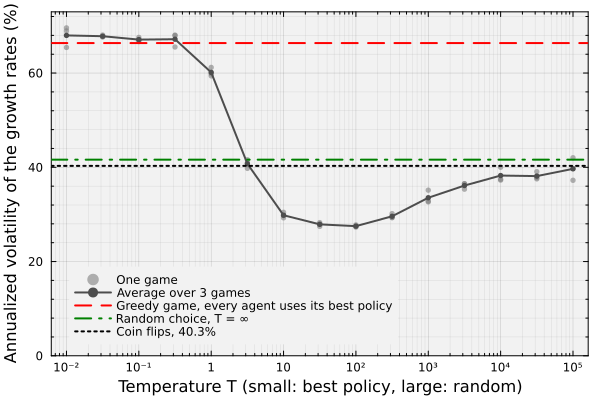

In [15]:
let

    # initialize: the average over the games at each temperature, the finite temperatures, and the averages at the two limits -
    temperature_mean_df = combine(groupby(temperature_df, :temperature, sort = true), :volatility => mean => :mean_volatility); # one row per temperature
    finite_games = filter(:temperature => T -> 0 < T < Inf, temperature_df); # games at finite, nonzero temperatures
    finite_means = filter(:temperature => T -> 0 < T < Inf, temperature_mean_df); # their averages
    greedy = only(temperature_mean_df.mean_volatility[temperature_mean_df.temperature .== 0.0]); # average annualized volatility (%) in the greedy game
    random_choice = only(temperature_mean_df.mean_volatility[isinf.(temperature_mean_df.temperature)]); # average annualized volatility (%) at T = ∞

    # plot: one faint point per game, and the averages over the games -
    scatter(finite_games.temperature, finite_games.volatility, ms = 3, msw = 0, c = :gray50, alpha = 0.6, label = "One game",
        xscale = :log10, xticks = (10.0 .^ (-2:5), ["10⁻²", "10⁻¹", "1", "10", "10²", "10³", "10⁴", "10⁵"]), # one tick per factor of ten
        ylims = (0, 1.1*greedy), # start the axis at zero
        bg = "gray95", background_color_outside = "white", framestyle = :box, fg_legend = :transparent,
        xminorticks = true, yminorticks = true, minorgrid = true, legend = :bottomleft)
    plot!(finite_means.temperature, finite_means.mean_volatility, lw = 2, c = :gray30, marker = :circle, ms = 3, msw = 0,
        label = "Average over $(number_of_seeds) games") # the averages
    hline!([greedy], lw = 2, c = :red, ls = :dash, label = "Greedy game, every agent uses its best policy") # the crowded game of Task 1 (the same color)
    hline!([random_choice], lw = 2, c = :green, ls = :dashdot, label = "Random choice, T = ∞") # the T = ∞ limit
    hline!([coin_flip_volatility], lw = 2, c = :black, ls = :dot, label = "Coin flips, $(round(coin_flip_volatility, digits = 1))%") # agents who flip fair coins

    # labels -
    xlabel!("Temperature T (small: best policy, large: random)", fontsize = 18)
    ylabel!("Annualized volatility of the growth rates (%)", fontsize = 18)
end

> __What do we see?__
>
> * __Low temperatures:__ Up to about $T=0.3$, the price volatility stays near the greedy line. For the agent in the table above, a temperature this small compared with $\Delta$ gives its best policy a probability close to 1.
> * __Intermediate temperatures:__ Between about $T=1$ and $T=10$, the volatility drops by about half and crosses the random-choice line. From about $T=10$ to $T=1{,}000$ it stays well below both the greedy line and the random-choice line, with its smallest value near $T=100$.
> * __High temperatures:__ Above about $T=1{,}000$, the volatility rises back toward the random-choice line.

When every agent always uses its best policy, agents with the same best policy switch together, and the price is most volatile. Some randomness in the choice spreads out those switches, and the price is less volatile than at either limit.

___

## Summary
In this example, we simulated the minority game, let the attendance move a price, and measured how the memory and the temperature change the volatility of that price.

> __Key Takeaways:__
>
> * __A few rules produce a measurable aggregate:__ We simulated agents who each buy or sell with one of several fixed policies, scored every policy after each round, and recorded the attendance. The volatility of the attendance per agent let us compare the whole population with agents who flip coins.
>
>   When we let the attendance move a price, the crowded game moved it more than the longer-memory game. Its growth rates had mild fat tails but almost no volatility clustering.
> * __The overlap in the agents' policies sets the price volatility:__ We varied the memory with the same number of agents, liquidity, and $\sigma_{S}$, and measured the annualized volatility of the growth rates. With a short memory, many agents held similar policies, and the price was more volatile than in a market of agents who flip coins.
>
>   At an intermediate memory, the volatility fell well below the coin-flip value.
> * __Some randomness in the policy choice lowers the price volatility:__ We varied the temperature of the Boltzmann choice rule in the crowded game. Low temperatures gave the volatility of the greedy game, high temperatures approached random choice, and in between the price volatility fell below both limits.

The agents, the history they see, their rule for choosing a policy, the attendance, and the scores that feed the attendance back into the next choice are the five parts of an agent-based model from the lecture.
___

## Disclaimer and Risks
__This content is offered solely for training and informational purposes__. No offer or solicitation to buy or sell securities or derivative products or any investment or trading advice or strategy is made, given, or endorsed by the teaching team.

__Trading involves risk__. Carefully review your financial situation before investing in securities, futures contracts, options, or commodity interests. Past performance, whether actual or indicated by historical tests of strategies, is no guarantee of future performance or success. Trading is generally inappropriate for someone with limited resources, investment or trading experience, or a low-risk tolerance. Only risk capital that is not required for living expenses should be used.

__You are fully responsible for any investment or trading decisions you make__. Such decisions should be based solely on evaluating your financial circumstances, investment or trading objectives, risk tolerance, and liquidity needs.

___